### Background subtraction test visualization

In [1]:
import sys
sys.path.append('/home/smarci/python_libs')

from poloidal_flow import ABESConfig, ABESDataReader, CorrelationAnalysis, CorrelationConfig
import flap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors

mpl.rcParams.update({
    'font.size': 12
})

config = ABESConfig(
    exp_id = '20250409.046', 
    time_range = [5, 5.001],
    #channels = [14],
    bandpass_type = None
)

reader = ABESDataReader(config)

reader.read_data_raw()
raw = reader.raw_data

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [2]:
on0, off, backsub0 = reader.background_subtraction(deflection = 0)
on1, off, backsub1 = reader.background_subtraction(deflection = 1)

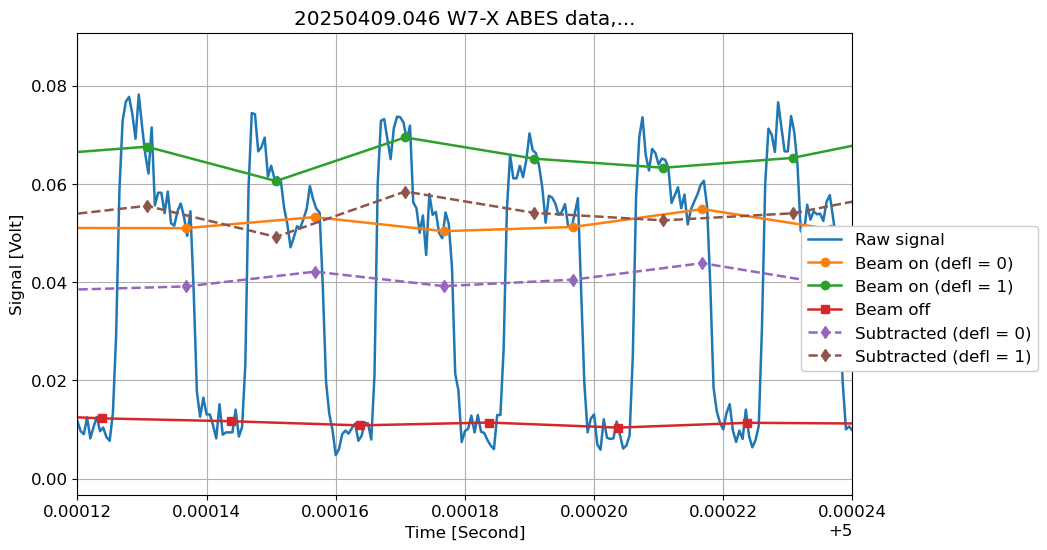

In [9]:
plt.figure(figsize = (10, 6))

raw.plot(axes = 'Time', plot_options = {'label': 'Raw signal', 'lw': 1.8}, slicing = {'Channel': 14})
on0.plot(axes = 'Time', plot_options = {'marker': 'o', 'label': 'Beam on (defl = 0)', 'lw': 1.8}, slicing = {'Channel': 14})
on1.plot(axes = 'Time', plot_options = {'marker': 'o', 'label': 'Beam on (defl = 1)', 'lw': 1.8}, slicing = {'Channel': 14})
off.plot(axes = 'Time', plot_options = {'marker': 's', 'label': 'Beam off', 'lw': 1.8}, slicing = {'Channel': 14})
backsub0.plot(axes = 'Time', plot_options = {'marker': 'd', 'label': 'Subtracted (defl = 0)', 'lw': 1.8, 'ls': 'dashed'}, slicing = {'Channel number': 14})
backsub1.plot(axes = 'Time', plot_options = {'marker': 'd', 'label': 'Subtracted (defl = 1)', 'lw': 1.8, 'ls': 'dashed'}, slicing = {'Channel number': 14})
# plt.plot(on0_time, bs, marker = 'o', c = 'k')

dt = 0.00012

plt.xlim([5 + 1*dt, 5 + 2*dt])
plt.legend(framealpha = True, bbox_to_anchor = (1.25, 0.6))
plt.grid()
plt.savefig('chop_backsub.pdf')